# jubii.7 · Track A: "Read the messy invoice"

One scanned page (a bilingual Arabic/English tax invoice and delivery note from **Al Waha Building
Materials**) goes in. Out come clean JSON, a list of every problem on the page, and a model that
puts each line item into **cement / steel / aggregates / blocks / services**, served as a `/predict` API.

| Task | Where |
|---|---|
| 1 Data understanding: extract, profile, recalculate, list problems | §1 |
| 2 Labelling: 5-line guide + AI-made lines, checked and fixed | §2 |
| 3 Model: TF-IDF + logistic regression | §3 |
| 4 MLflow: 3 runs compared, best one picked | §4 |
| 5 Evaluation: per-class P/R/F1, confusion matrix, mistakes | §5 |
| 6 Deployment: FastAPI `/predict`, live call | §6 |
| 7 Code & docs: README, known limits | §7 |

**Run all** (Runtime → Run all). Each `%%writefile` cell writes one file of the repo, so the notebook
*is* the repo: download it as a zip at the end.

In [1]:
import os, sys, subprocess, json, time, warnings
from pathlib import Path
import requests

warnings.filterwarnings("ignore")              # keep library warnings out of the outputs
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow", "fastapi", "uvicorn"], check=True)

if IN_COLAB:
    PROJECT = Path("/content/jubii7-track-a")
elif (Path.cwd() / "invoice_ml").exists():          # opened inside the cloned repo
    PROJECT = Path.cwd()
else:
    PROJECT = Path.cwd() / "jubii7-track-a"
for d in ["invoice_ml", "app", "data", "docs", "reports", "models"]:
    (PROJECT / d).mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
os.environ["PYTHONIOENCODING"] = "utf-8"
os.environ["PYTHONWARNINGS"] = "ignore"


def run(module, quiet=False):
    """Run `python -m <module>` (exactly what the README says) and show its output."""
    r = subprocess.run([sys.executable, "-m", module], capture_output=True, text=True, encoding="utf-8")
    if not quiet:
        print(r.stdout)
    if r.returncode:
        print(r.stderr[-3000:]); raise RuntimeError(f"{module} failed")


print("Running in Colab:", IN_COLAB, "| project folder:", PROJECT.name)

Running in Colab: False | project folder: jubii7-track-a


In [2]:
%%writefile invoice_ml/__init__.py
"""jubii.7 Track A - invoice reader, checker and line-item classifier."""

Overwriting invoice_ml/__init__.py


### Shared helper: normalise Arabic text and digits
The page mixes `٢٤` with `24` and `١٨` with `18`, and writes amounts as `(155.20)` or `1,500`.
Every number goes through `parse_number`, and every description goes through `normalize_text`
(which also unifies alef/taa-marbuta and drops diacritics) before the model sees it.
The amount in words is Arabic, so `arabic_words_to_number` turns it back into a figure.

In [3]:
%%writefile invoice_ml/text_utils.py
"""Helpers for messy bilingual (Arabic/English) invoice text.

Shared by the invoice checker, the training pipeline and the API, so the
pickled model can always find `normalize_text` on import.
"""
from __future__ import annotations

import re

# Arabic-Indic (U+0660..0669) and Eastern Arabic / Persian (U+06F0..06F9) digits
_DIGIT_MAP = {ord(c): str(i) for i, c in enumerate("٠١٢٣٤٥٦٧٨٩")}
_DIGIT_MAP.update({ord(c): str(i) for i, c in enumerate("۰۱۲۳۴۵۶۷۸۹")})
_DIGIT_MAP[ord("٫")] = "."   # Arabic decimal separator
_DIGIT_MAP[ord("٬")] = ","   # Arabic thousands separator
_DIGIT_MAP[ord("،")] = ","   # Arabic comma

_ARABIC_DIGITS_RE = re.compile(r"[٠-٩۰-۹]")
_WESTERN_DIGITS_RE = re.compile(r"[0-9]")
_DIACRITICS_RE = re.compile(r"[ً-ْٰ]")  # harakat
_TATWEEL = "ـ"


def to_western_digits(s: str) -> str:
    return s.translate(_DIGIT_MAP)


def digit_script(s: str | None) -> str:
    """Return 'arabic', 'western', 'mixed' or 'none' for the digits in s."""
    if not s:
        return "none"
    a = bool(_ARABIC_DIGITS_RE.search(s))
    w = bool(_WESTERN_DIGITS_RE.search(s))
    return "mixed" if a and w else "arabic" if a else "western" if w else "none"


def parse_number(value) -> float | None:
    """Parse '1,250.00', '١٬٢٥٠٫٠٠', 'AED 925', '' -> float or None."""
    if value is None:
        return None
    if isinstance(value, (int, float)):
        return float(value)
    s = to_western_digits(str(value)).strip()
    s = re.sub(r"[^\d.,\-]", "", s)  # drop currency, units, spaces
    if not s:
        return None
    s = s.replace(",", "")
    try:
        return float(s)
    except ValueError:
        return None


def _norm_ar(w: str) -> str:
    w = _DIACRITICS_RE.sub("", w.replace(_TATWEEL, ""))
    w = re.sub("[إأآا]", "ا", w)
    return w.replace("ى", "ي").replace("ة", "ه")


_AR_NUM = {_norm_ar(k): v for k, v in {
    "واحد": 1, "اثنان": 2, "اثنين": 2, "ثلاثة": 3, "ثلاث": 3, "أربعة": 4, "أربع": 4,
    "خمسة": 5, "خمس": 5, "ستة": 6, "ست": 6, "سبعة": 7, "سبع": 7, "ثمانية": 8, "ثماني": 8,
    "ثمان": 8, "تسعة": 9, "تسع": 9, "عشرة": 10, "عشر": 10, "أحد": 1, "اثنا": 2, "اثني": 2,
    "عشرون": 20, "عشرين": 20, "ثلاثون": 30, "ثلاثين": 30, "أربعون": 40, "أربعين": 40,
    "خمسون": 50, "خمسين": 50, "ستون": 60, "ستين": 60, "سبعون": 70, "سبعين": 70,
    "ثمانون": 80, "ثمانين": 80, "تسعون": 90, "تسعين": 90,
    "مائة": 100, "مئة": 100, "مائتان": 200, "مئتان": 200, "مائتين": 200, "مئتين": 200,
    "ثلاثمائة": 300, "ثلاثمئة": 300, "أربعمائة": 400, "أربعمئة": 400, "خمسمائة": 500,
    "خمسمئة": 500, "ستمائة": 600, "ستمئة": 600, "سبعمائة": 700, "سبعمئة": 700,
    "ثمانمائة": 800, "ثمانمئة": 800, "تسعمائة": 900, "تسعمئة": 900,
}.items()}
_AR_THOUSAND = {_norm_ar(w) for w in ("ألف", "ألفا", "آلاف")}
_AR_TWO_THOUSAND = {_norm_ar(w) for w in ("ألفان", "ألفين")}


def arabic_words_to_number(text: str) -> float | None:
    """'فقط ثلاثة وعشرون ألفاً وستمائة وستون درهماً وثلاثون فلساً لا غير' -> 23660.30"""
    total = current = 0
    dirhams = None
    seen = False
    for raw in text.split():
        w = _norm_ar(raw)
        if w not in _AR_NUM and w.startswith("و") and len(w) > 2:
            w = w[1:]                                   # conjunction "wa-"
        if w in _AR_NUM:
            current += _AR_NUM[w]; seen = True
        elif w in _AR_THOUSAND:
            total += max(current, 1) * 1000; current = 0; seen = True
        elif w in _AR_TWO_THOUSAND:
            total += 2000; seen = True
        elif w.startswith("درهم"):
            dirhams = total + current; total = current = 0
        elif w.startswith("فلس"):
            break
    if not seen:
        return None
    if dirhams is None:                                # no "dirham" word
        return float(total + current)
    return round(dirhams + (total + current) / 100, 2)


def normalize_text(s: str) -> str:
    """Normalise a line-item description before vectorising.

    - Arabic digits -> Western digits (so '٥٠ كجم' and '50 كجم' match)
    - unify alef/yaa/taa-marbuta variants, strip diacritics and tatweel
    - lowercase, collapse whitespace
    """
    s = to_western_digits(s)
    s = s.replace(_TATWEEL, "")
    s = _DIACRITICS_RE.sub("", s)
    s = re.sub("[إأآا]", "ا", s)
    s = s.replace("ى", "ي").replace("ة", "ه")
    s = s.lower()
    return re.sub(r"\s+", " ", s).strip()

Overwriting invoice_ml/text_utils.py


In [4]:
from invoice_ml.text_utils import parse_number, arabic_words_to_number, normalize_text
print(parse_number("٢٤"), parse_number("1,500"), parse_number("(155.20)"), parse_number("١٫٨"))
print(arabic_words_to_number("فقط ثلاثة وعشرون ألفاً وستمائة وستون درهماً وثلاثون فلساً لا غير"))
print(normalize_text("أسمنت بورتلاند ٥٠ كجم"))

24.0 1500.0 155.2 1.8
23660.3
اسمنت بورتلاند 50 كجم


## 1 · Data understanding

**Extraction.** The scan is transcribed to JSON (vision LLM + the prompt in `docs/PROMPTS.md`, then
checked by eye) with every value **exactly as printed**: Arabic digits, commas, brackets, blanks.
Fixing values during extraction would hide the very errors the finance team needs to catch.
Uncertain reads go in `_low_confidence`.

In [5]:
%%writefile data/invoice_extracted.json
{
  "_note": "Transcribed from the scanned jubii.7 sample page. Values are kept EXACTLY as printed (raw strings, Arabic digits included); the checker does the normalising.",
  "_low_confidence": [
    "supplier.trn and customer.trn: photo is slightly blurred, zero count should be re-checked on paper",
    "totals_printed.vat_amount: read as 1,131.50"
  ],
  "document": {
    "title_en": "TAX INVOICE & DELIVERY NOTE",
    "title_ar": "فاتورة ضريبية وإشعار تسليم",
    "invoice_no": "WB-2026-11-0457",
    "invoice_date": "14/11/2026",
    "po_no": "NK/PO/٢٠٢٦/٣٨٩",
    "salesman": "خالد م.",
    "delivery_to": "مشروع فيلا سكنية - القطعة ٢١٧، منطقة الياسمين، عجمان",
    "payment_methods_ticked": ["Cash", "Credit"],
    "currency": "AED"
  },
  "supplier": {
    "name_en": "AL WAHA BUILDING MATERIALS TRADING LLC",
    "name_ar": "الواحة لتجارة مواد البناء ذ.م.م",
    "address": "Industrial Area 4, Sharjah, UAE",
    "phone": "06 000 0000",
    "trn": "100000000000003"
  },
  "customer": {
    "name_ar": "مؤسسة النخيل للمقاولات العامة",
    "trn": "100000000000817"
  },
  "sections": [
    {
      "name_en": "Site A - Foundation",
      "name_ar": "الموقع أ - الأساسات",
      "items": [
        {"line": 1, "description_en": "Portland cement 50 kg", "description_ar": "أسمنت بورتلاند ٥٠ كجم", "unit": "كيس", "qty_ordered": "120", "qty_delivered": "120", "unit_price": "18.50", "amount": "2,220.00"},
        {"line": 2, "description_en": "Rebar 12 mm", "description_ar": "حديد تسليح ١٢ مم", "unit": "طن", "qty_ordered": "4", "qty_delivered": "4", "unit_price": "2,750.00", "amount": "11,000.00"},
        {"line": 3, "description_en": "Washed sand", "description_ar": "رمل مغسول", "unit": "m³", "qty_ordered": "٢٤", "qty_delivered": "٢٤", "unit_price": "65.00", "amount": "1,650.00"}
      ],
      "subtotal_printed": "14,870.00"
    },
    {
      "name_en": "Site B - Walls & roof",
      "name_ar": "الموقع ب - الجدران والسقف",
      "items": [
        {"line": 4, "description_en": "Concrete block 20 cm", "description_ar": "بلوك خرساني ٢٠ سم", "unit": "حبة", "qty_ordered": "1,500", "qty_delivered": "1,500", "unit_price": "3.20", "amount": "4,800.00"},
        {"line": 5, "description_en": "Waterproofing membrane", "description_ar": "رول عزل مائي", "unit": "رول", "qty_ordered": "٢٠", "qty_delivered": "١٨", "unit_price": "145.00", "amount": "2,610.00"},
        {"line": 6, "description_en": "Delivery charge", "description_ar": "رسوم التوصيل", "unit": "رحلة", "qty_ordered": "1", "qty_delivered": "1", "unit_price": "350.00", "amount": "350.00"}
      ],
      "subtotal_printed": "7,760.00"
    }
  ],
  "totals_printed": {
    "total_before_discount": "22,630.00",
    "discount_label": "Discount 2% on Site B",
    "discount": "(155.20)",
    "taxable_amount": "22,474.80",
    "vat_rate": "5%",
    "vat_amount": "1,131.50",
    "grand_total": "23,606.30"
  },
  "amount_in_words_ar": "فقط ثلاثة وعشرون ألفاً وستمائة وستون درهماً وثلاثون فلساً لا غير",
  "deliveries": [
    {"delivery": "D1", "items": "1, 2, 3", "planned_date": "12/11/2026", "driver": "راشد", "vehicle": "SHJ 3 - 45120", "received_by": "م. سعيد", "note": null},
    {"delivery": "D2", "items": "4, 6", "planned_date": "15/11/2026", "driver": "راشد", "vehicle": "SHJ 3 - 45120", "received_by": "م. سعيد", "note": null},
    {"delivery": "D3", "items": "5", "planned_date": "31/11/2026", "driver": "يوسف", "vehicle": "AJM 8 - 7781", "received_by": null, "note": "balance 2 rolls pending (handwritten)"}
  ],
  "terms_en": "Payment due within 45 days of invoice date. Goods once delivered are not returnable. Prices include delivery inside Sharjah only.",
  "terms_ar": "يستحق الدفع خلال ٣٠ يوماً من تاريخ الفاتورة. البضاعة المسلمة لا ترد. الأسعار تشمل التوصيل داخل الشارقة فقط.",
  "signatures": {"prepared_by": null, "checked_by": null, "customer_signature": null},
  "stamp": {"present": true, "text": "AL WAHA TRADING SHARJAH", "position": "next to the customer signature box; signature itself is blank"}
}

Overwriting data/invoice_extracted.json


**Checker.** It profiles every field (type and digit script), then recalculates line by line:
amount = delivered qty × price, then section subtotals, total before discount, the 2% Site B discount,
taxable amount, 5% VAT, grand total and the amount in words. Each total is compared **two ways**:
- against the *printed* figures above it, which shows where the page's own arithmetic broke
- against the *full recalculation*, which gives what the number should be

It also cross-checks the delivery table (dates, receivers, trips), English vs Arabic terms, the payment
boxes, TRNs, signatures and the stamp.

In [6]:
%%writefile invoice_ml/check_invoice.py
"""Task 1 - Data understanding: profile the extracted invoice, recalculate
every total and list every problem found.

Usage:  python -m invoice_ml.check_invoice [data/invoice_extracted.json]
Writes: reports/invoice_profile.csv, reports/invoice_problems.csv,
        reports/invoice_clean.json
"""
from __future__ import annotations

import json
import re
import sys
from datetime import date, datetime, timedelta
from pathlib import Path

import pandas as pd

from invoice_ml.text_utils import (arabic_words_to_number, digit_script, parse_number,
                                   to_western_digits)

ROOT = Path(__file__).resolve().parents[1]
REPORTS = ROOT / "reports"
TOL = 0.01  # AED rounding tolerance
SEVERITY_ORDER = {"high": 0, "medium": 1, "low": 2, "info": 3}


# ---------------------------------------------------------------- profiling
def _infer_type(key: str, value) -> str:
    if value is None or value == "":
        return "missing"
    if isinstance(value, bool):
        return "bool"
    if isinstance(value, (int, float)):
        return "number"
    s = to_western_digits(str(value))
    if "date" in key:
        return "date"
    if key in {"trn", "invoice_no", "po_no", "phone", "vehicle"}:
        return "id"
    if re.fullmatch(r"\(?[\d.,\s%]+\)?", s):
        return "number"
    return "text"


def _walk(obj, path=""):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if not k.startswith("_"):
                yield from _walk(v, f"{path}.{k}" if path else k)
    elif isinstance(obj, list):
        for i, v in enumerate(obj):
            yield from _walk(v, f"{path}[{i}]")
    else:
        yield path, obj


def profile(inv: dict) -> pd.DataFrame:
    rows = []
    for path, value in _walk(inv):
        key = re.sub(r"\[\d+\]", "", path).split(".")[-1]
        rows.append({"field": path, "value": value, "type": _infer_type(key, value),
                     "digits": digit_script(value if isinstance(value, str) else None)})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- helpers
def parse_date(s: str | None) -> date | None:
    if not s:
        return None
    s = to_western_digits(s).strip()
    for fmt in ("%d/%m/%Y", "%Y-%m-%d", "%d-%m-%Y", "%d.%m.%Y"):
        try:
            return datetime.strptime(s, fmt).date()
        except ValueError:
            pass
    return None


def money(x: float) -> float:
    return round(x + 1e-9, 2)


def days_in_terms(text: str | None) -> int | None:
    m = re.search(r"(\d+)\s*(?:days|يوم)", to_western_digits(text or ""))
    return int(m.group(1)) if m else None


# ---------------------------------------------------------------- checks
def check(inv: dict) -> tuple[dict, pd.DataFrame]:
    problems: list[dict] = []

    def flag(severity, field, issue, printed=None, expected=None):
        problems.append({"severity": severity, "field": field, "issue": issue,
                         "printed": printed, "expected": expected})

    doc, sup, cus = inv["document"], inv["supplier"], inv["customer"]
    inv_date = parse_date(doc.get("invoice_date"))

    # --- header
    for party, data in (("supplier", sup), ("customer", cus)):
        trn = data.get("trn")
        if not trn:
            flag("high", f"{party}.trn", "TRN missing")
        elif len(re.sub(r"\D", "", to_western_digits(trn))) != 15:
            flag("high", f"{party}.trn", "UAE TRN must be 15 digits", printed=trn)
    ticked = doc.get("payment_methods_ticked") or []
    if len(ticked) != 1:
        flag("medium", "document.payment", f"{len(ticked)} payment methods ticked "
             f"({', '.join(ticked) or 'none'}) - Cash and Credit contradict each other",
             printed=ticked)
    for k in ("po_no",):
        if digit_script(doc.get(k)) in ("arabic", "mixed"):
            flag("info", f"document.{k}", "Arabic-Indic digits in an ID - normalise before "
                 "matching to the PO system", printed=doc[k],
                 expected=to_western_digits(doc[k]))

    # --- line items
    sections_out, total_correct, total_printed_lines = [], 0.0, 0.0
    for sec in inv["sections"]:
        s_correct = s_printed = 0.0
        items_out = []
        for it in sec["items"]:
            ref = f"line {it['line']} ({it['description_en']})"
            q_ord, q_del, price, amount = (parse_number(it.get(k)) for k in
                                           ("qty_ordered", "qty_delivered", "unit_price", "amount"))
            for k in ("qty_ordered", "qty_delivered", "unit_price", "amount"):
                if digit_script(it.get(k)) == "arabic":
                    flag("info", f"{ref}.{k}", "Arabic-Indic digits, normalised",
                         printed=it[k], expected=parse_number(it[k]))
            billed_qty = q_del if q_del is not None else q_ord
            if q_ord is not None and q_del is not None and q_ord != q_del:
                flag("medium", f"{ref}.qty", f"Ordered {q_ord:g} but delivered {q_del:g}: "
                     "billed on delivered qty, balance must not be billed twice later",
                     printed=f"{q_ord:g} / {q_del:g}")
            if billed_qty is None or price is None:
                flag("high", ref, "Cannot recalculate: qty or unit price missing")
                correct = amount or 0.0
            else:
                correct = money(billed_qty * price)
                if amount is None:
                    flag("high", f"{ref}.amount", "Amount missing", expected=correct)
                elif abs(correct - amount) > TOL:
                    hint = ""
                    if sorted(f"{amount:.2f}") == sorted(f"{correct:.2f}"):
                        hint = " - same digits, looks like a transposition"
                    flag("high", f"{ref}.amount",
                         f"qty x price = {billed_qty:g} x {price:,.2f}{hint}",
                         printed=amount, expected=correct)
            s_correct += correct
            s_printed += amount or 0.0
            items_out.append({**it, "qty_ordered": q_ord, "qty_delivered": q_del,
                              "unit_price": price, "amount_printed": amount,
                              "amount": correct})

        sub_p = parse_number(sec.get("subtotal_printed"))
        if sub_p is None or abs(sub_p - money(s_correct)) > TOL:
            carried = sub_p is not None and abs(sub_p - money(s_printed)) <= TOL
            flag("high", f"{sec['name_en']}.subtotal", "Section subtotal wrong" +
                 (" (adds up the printed lines, so the line error carried through)" if carried
                  else " (does not match the printed lines either)"),
                 printed=sub_p, expected=money(s_correct))
        total_correct += s_correct
        total_printed_lines += s_printed
        sections_out.append({"name_en": sec["name_en"], "name_ar": sec["name_ar"],
                             "items": items_out, "subtotal": money(s_correct),
                             "subtotal_printed": sub_p})

    # --- totals: check each step against the PRINTED previous step (where did it
    #     break?) and against the full recalculation (what should it be?)
    t = inv["totals_printed"]
    p = {k: parse_number(t.get(k)) for k in
         ("total_before_discount", "discount", "taxable_amount", "vat_amount", "grand_total")}
    p["discount"] = abs(p["discount"] or 0.0)        # printed as "(155.20)"
    vat_rate = (parse_number(t.get("vat_rate")) or 5.0) / 100
    if abs(vat_rate - 0.05) > 1e-9:
        flag("high", "totals.vat_rate", "UAE standard VAT rate is 5%", printed=t["vat_rate"])

    m = re.search(r"([\d.]+)\s*%\s*on\s*(.+)", t.get("discount_label") or "", re.I)
    disc_rate = float(m.group(1)) / 100 if m else 0.0
    disc_target = m.group(2).strip().lower() if m else ""
    disc_secs = [s for s in sections_out if disc_target and disc_target in s["name_en"].lower()]
    disc_base_correct = sum(s["subtotal"] for s in disc_secs) if disc_secs else total_correct
    disc_base_printed = (sum(s["subtotal_printed"] for s in disc_secs) if disc_secs
                         else p["total_before_discount"])
    if disc_secs and any("delivery" in i["description_en"].lower()
                         for s in disc_secs for i in s["items"]):
        flag("low", "totals.discount", "Discount base includes the delivery charge - "
             "confirm the discount is meant to apply to services too")

    c = {}
    c["total_before_discount"] = money(total_correct)
    c["discount"] = money(disc_base_correct * disc_rate)
    c["taxable_amount"] = money(c["total_before_discount"] - c["discount"])
    c["vat_amount"] = money(c["taxable_amount"] * vat_rate)
    c["grand_total"] = money(c["taxable_amount"] + c["vat_amount"])

    printed_chain = {
        "total_before_discount": sum(s["subtotal_printed"] or 0 for s in sections_out),
        "discount": money(disc_base_printed * disc_rate),
        "taxable_amount": money(p["total_before_discount"] - p["discount"]),
        "vat_amount": money(p["taxable_amount"] * vat_rate),
        "grand_total": money(p["taxable_amount"] + p["vat_amount"]),
    }
    for k in c:
        if abs(p[k] - printed_chain[k]) > TOL:
            flag("high", f"totals.{k}", "Arithmetic error on the page: does not follow from "
                 "the printed figures above it", printed=p[k], expected=printed_chain[k])
        elif abs(p[k] - c[k]) > TOL:
            flag("high", f"totals.{k}", "Wrong after recalculation (error carried from above)",
                 printed=p[k], expected=c[k])

    words = inv.get("amount_in_words_ar")
    if words:
        w = arabic_words_to_number(words)
        if w is None:
            flag("medium", "amount_in_words", "Could not parse amount in words", printed=words)
        elif abs(w - p["grand_total"]) > TOL:
            hint = (" - same digits, looks like a transposition"
                    if sorted(f"{w:.2f}") == sorted(f"{p['grand_total']:.2f}") else "")
            flag("high", "amount_in_words", f"Words say {w:,.2f} but the figure says "
                 f"{p['grand_total']:,.2f}{hint}", printed=w, expected=c["grand_total"])

    # --- deliveries vs invoice
    for d in inv.get("deliveries", []):
        ref = f"delivery {d['delivery']}"
        dd = parse_date(d.get("planned_date"))
        if d.get("planned_date") and dd is None:
            flag("high", f"{ref}.planned_date", "Invalid calendar date", printed=d["planned_date"])
        elif dd and inv_date and dd > inv_date:
            status = "but is marked received" if d.get("received_by") else "and is not received"
            flag("medium", f"{ref}.planned_date", f"Delivery is after the invoice date {status}; "
                 "its items are billed as already delivered", printed=d["planned_date"])
        if not d.get("received_by"):
            flag("medium", f"{ref}.received_by", "No receiver - goods not confirmed delivered"
                 + (f" ({d['note']})" if d.get("note") else ""))
    trips = len(inv.get("deliveries", []))
    del_lines = [i for s in sections_out for i in s["items"]
                 if "delivery" in i["description_en"].lower()]
    for i in del_lines:
        if i["qty_delivered"] and trips and i["qty_delivered"] != trips:
            flag("low", f"line {i['line']} (Delivery charge)", f"Charged {i['qty_delivered']:g} "
                 f"trip but the delivery table shows {trips} trips", printed=i["qty_delivered"],
                 expected=trips)
    if "sharjah only" in (inv.get("terms_en") or "").lower() and \
            "عجمان" in (doc.get("delivery_to") or ""):
        flag("low", "document.delivery_to", "Delivery address is in Ajman but prices only "
             "include delivery inside Sharjah - check the delivery charge")

    # --- terms, signatures, stamp
    d_en, d_ar = days_in_terms(inv.get("terms_en")), days_in_terms(inv.get("terms_ar"))
    if d_en and d_ar and d_en != d_ar:
        flag("high", "terms", f"English terms say {d_en} days, Arabic terms say {d_ar} days",
             printed=f"{d_en} / {d_ar}")
    if inv_date and d_en:
        flag("info", "terms.due_date", "Due date implied by terms",
             expected=f"{inv_date + timedelta(days=d_en)} (EN) / "
                      f"{inv_date + timedelta(days=d_ar or d_en)} (AR)")
    for k, v in (inv.get("signatures") or {}).items():
        if not v:
            flag("medium", f"signatures.{k}", "Blank")
    stamp = inv.get("stamp") or {}
    if stamp.get("present") and not (inv.get("signatures") or {}).get("customer_signature"):
        flag("low", "stamp", "Supplier stamp present but customer signature blank")

    clean = {"document": {**doc, "invoice_date": str(inv_date)},
             "supplier": sup, "customer": cus, "sections": sections_out,
             "totals_printed": p, "totals_recalculated": c,
             "deliveries": inv.get("deliveries")}
    df = pd.DataFrame(problems)
    df = df.sort_values("severity", key=lambda s: s.map(SEVERITY_ORDER), kind="stable")
    return clean, df.reset_index(drop=True)


def main(path: str | None = None) -> None:
    src = Path(path) if path else ROOT / "data" / "invoice_extracted.json"
    inv = json.loads(src.read_text(encoding="utf-8"))
    REPORTS.mkdir(exist_ok=True)

    prof = profile(inv)
    prof.to_csv(REPORTS / "invoice_profile.csv", index=False, encoding="utf-8-sig")
    clean, problems = check(inv)
    (REPORTS / "invoice_clean.json").write_text(
        json.dumps(clean, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    problems.to_csv(REPORTS / "invoice_problems.csv", index=False, encoding="utf-8-sig")

    print(f"Profiled {len(prof)} fields: {prof['type'].value_counts().to_dict()}")
    print(f"Digit scripts: {prof['digits'].value_counts().to_dict()}")
    print("\nTotals (printed -> recalculated):")
    for k, v in clean["totals_recalculated"].items():
        print(f"  {k:22} {clean['totals_printed'][k]:>12,.2f} -> {v:>12,.2f}")
    print(f"\n{len(problems)} problems ({problems['severity'].value_counts().to_dict()}):")
    for r in problems.itertuples():
        extra = ""
        if r.printed is not None or r.expected is not None:
            extra = f"  [printed={r.printed} expected={r.expected}]"
        print(f"  {r.severity.upper():6} {r.field}: {r.issue}{extra}")


if __name__ == "__main__":
    main(sys.argv[1] if len(sys.argv) > 1 else None)

Overwriting invoice_ml/check_invoice.py


In [7]:
import pandas as pd
pd.set_option("display.max_colwidth", 120)
from invoice_ml.check_invoice import profile, check

inv = json.loads(Path("data/invoice_extracted.json").read_text(encoding="utf-8"))
prof = profile(inv)
print("Field types:", prof["type"].value_counts().to_dict())
print("Digit scripts:", prof["digits"].value_counts().to_dict())
display(prof[prof["digits"].isin(["arabic", "mixed"]) | (prof["type"] == "missing")])

Field types: {'text': 48, 'number': 41, 'id': 8, 'missing': 6, 'date': 4, 'bool': 1}
Digit scripts: {'western': 52, 'none': 46, 'arabic': 10}


,field,value,type,digits
4,document.po_no,NK/PO/٢٠٢٦/٣٨٩,id,arabic
6,document.delivery_to,مشروع فيلا سكنية - القطعة ٢١٧، منطقة الياسمين، عجمان,text,arabic
21,sections[0].items[0].description_ar,أسمنت بورتلاند ٥٠ كجم,text,arabic
29,sections[0].items[1].description_ar,حديد تسليح ١٢ مم,text,arabic
39,sections[0].items[2].qty_ordered,٢٤,number,arabic
40,sections[0].items[2].qty_delivered,٢٤,number,arabic
48,sections[1].items[0].description_ar,بلوك خرساني ٢٠ سم,text,arabic
58,sections[1].items[1].qty_ordered,٢٠,number,arabic
59,sections[1].items[1].qty_delivered,١٨,number,arabic
85,deliveries[0].note,None,missing,none


In [8]:
clean, problems = check(inv)
totals = pd.DataFrame({"printed": clean["totals_printed"], "recalculated": clean["totals_recalculated"]})
totals["difference"] = totals["printed"] - totals["recalculated"]
display(totals.style.format("{:,.2f}"))
print(f"{len(problems)} problems:", problems["severity"].value_counts().to_dict())
display(problems)

,printed,recalculated,difference
total_before_discount,"22,630.00","22,540.00",90.00
discount,155.20,155.20,0.00
taxable_amount,"22,474.80","22,384.80",90.00
vat_amount,"1,131.50","1,119.24",12.26
grand_total,"23,606.30","23,504.04",102.26


26 problems: {'high': 9, 'medium': 7, 'info': 6, 'low': 4}


,severity,field,issue,printed,expected
0,high,line 3 (Washed sand).amount,"qty x price = 24 x 65.00 - same digits, looks like a transposition",1650.0,1560.0
1,high,Site A - Foundation.subtotal,"Section subtotal wrong (adds up the printed lines, so the line error carried through)",14870.0,14780.0
2,high,totals.total_before_discount,Wrong after recalculation (error carried from above),22630.0,22540.0
3,high,totals.taxable_amount,Wrong after recalculation (error carried from above),22474.8,22384.8
4,high,totals.vat_amount,Arithmetic error on the page: does not follow from the printed figures above it,1131.5,1123.74
5,high,totals.grand_total,Wrong after recalculation (error carried from above),23606.3,23504.04
6,high,amount_in_words,"Words say 23,660.30 but the figure says 23,606.30 - same digits, looks like a transposition",23660.3,23504.04
7,high,delivery D3.planned_date,Invalid calendar date,31/11/2026,None
8,high,terms,"English terms say 45 days, Arabic terms say 30 days",45 / 30,None
9,medium,document.payment,"2 payment methods ticked (Cash, Credit) - Cash and Credit contradict each other","[Cash, Credit]",None


In [9]:
# Save the clean JSON + reports (same as: python -m invoice_ml.check_invoice)
run("invoice_ml.check_invoice", quiet=True)
print(json.dumps(clean["sections"][0]["items"][2], ensure_ascii=False, indent=2))

{
  "line": 3,
  "description_en": "Washed sand",
  "description_ar": "رمل مغسول",
  "unit": "m³",
  "qty_ordered": 24.0,
  "qty_delivered": 24.0,
  "unit_price": 65.0,
  "amount": 1560.0,
  "amount_printed": 1650.0
}


**What the page gets wrong (headline):** the customer is charged **AED 23,606.30** instead of **AED 23,504.04**,
an overcharge of **AED 102.26** caused by two independent errors (1 and 2 below).
1. Line 3, washed sand: 24 × 65 = **1,560**, printed **1,650** (digit swap). It flows into the Site A
   subtotal, total before discount, taxable amount and grand total.
2. VAT printed **1,131.50**, but 5% of the printed taxable amount (22,474.80) is 1,123.74. This is a second, independent error.
3. Amount in words says **23,660.30**, the figure says **23,606.30**, and the correct total is **23,504.04**.
4. Delivery D3 is dated **31/11/2026**, which doesn't exist. D2 (15/11) is after the invoice date (14/11) yet marked received.
5. English terms say **45 days**, Arabic terms say **30 days**.
6. Both **Cash** and **Credit** are ticked. The membrane is billed for 18 of 20 ordered with 2 still pending.
   There are 3 trips but 1 delivery charge, the address is in Ajman while prices cover "Sharjah only", and every signature is blank.
7. Open question for finance: the 2% Site B discount is also applied to the delivery charge. Is that intended?

The full list of all problems, with severity and printed vs expected values, is the table above.

## 2 · Data labelling

**Labelling guide (5 rules)**
1. Label what is being bought, not words in the name. Ignore sizes, units, brands.
2. **cement**: cement and products made mainly of it (ready-mix, mortar, cement adhesive, additives).
3. **blocks**: any finished unit laid by hand (concrete/hollow/AAC blocks, bricks, kerbs). "Concrete block" is **blocks**.
4. **steel**: steel products only. **services**: labour, transport, hire, fees, *even if steel/concrete is mentioned*.
5. **aggregates**: sand, gravel, crushed stone, whatever the unit. If a line fits no class, label it
   `out_of_scope`. Never force it.

The 6 invoice lines plus 63 AI-generated lines (English and Arabic) were labelled. Every AI label was checked against the
guide: `ai_label` is what the AI said, `label` is the corrected one, and `review_note` says why.

In [10]:
%%writefile data/line_items_labelled.csv
text,lang,source,ai_label,label,review_note
Portland cement 50 kg / أسمنت بورتلاند ٥٠ كجم,mixed,invoice,cement,cement,
Rebar 12 mm / حديد تسليح ١٢ مم,mixed,invoice,steel,steel,
Washed sand / رمل مغسول,mixed,invoice,aggregates,aggregates,
Concrete block 20 cm / بلوك خرساني ٢٠ سم,mixed,invoice,cement,blocks,AI said cement because of 'concrete'; guide rule 3: finished blocks are blocks
Waterproofing membrane / رول عزل مائي,mixed,invoice,cement,out_of_scope,Not cement/steel/aggregates/blocks/services - excluded from training; needs a new class (e.g. waterproofing/other)
Delivery charge / رسوم التوصيل,mixed,invoice,services,services,
Ordinary Portland Cement 50kg bag,en,ai,cement,cement,
Rebar T16 16mm,en,ai,steel,steel,
Gravel 20mm,en,ai,aggregates,aggregates,
Hollow block 20cm,en,ai,blocks,blocks,
Crane offloading per hour,en,ai,services,services,
Sulphate resistant cement SRC 50kg,en,ai,cement,cement,
Ordinary Portland Cement Type I bulk,en,ai,cement,cement,
Ready-mix concrete C40 per m3,en,ai,cement,cement,
Masonry cement 40kg bag,en,ai,cement,cement,
Tile adhesive cement based 20kg,en,ai,cement,cement,
Rapid hardening cement,en,ai,cement,cement,
اسمنت مقاوم للكبريتات ٥٠ كجم,ar,ai,cement,cement,
اسمنت عادي كيس ٤٠ كيلو,ar,ai,cement,cement,
خرسانة جاهزة متر مكعب,ar,ai,aggregates,cement,AI said aggregates; guide rule 2: ready-mix is cement-based
اسمنت ابيض للتشطيب,ar,ai,cement,cement,
Cement mortar dry mix 25kg,en,ai,cement,cement,
Deformed steel bar 10mm Grade 60,en,ai,steel,steel,
Mild steel round bar 8mm,en,ai,steel,steel,
Steel mesh A193 sheet,en,ai,steel,steel,
Black annealed binding wire,en,ai,steel,steel,
GI pipe 2 inch 6m length,en,ai,steel,steel,
Steel angle 50x50x5,en,ai,steel,steel,
Rebar coupler T20,en,ai,steel,steel,
حديد تسليح ٨ مم,ar,ai,steel,steel,
شبك حديد ملحوم,ar,ai,steel,steel,
سلك ربط مجلفن,ar,ai,steel,steel,
حديد زاوية ٤٠ مم,ar,ai,steel,steel,
Rebar cutting and bending service,en,ai,steel,services,AI said steel; guide rule 4: labour on materials is services
Dune sand per truck,en,ai,aggregates,aggregates,
Crushed stone 10mm,en,ai,aggregates,aggregates,
Gabbro aggregate 20mm,en,ai,aggregates,aggregates,
Road base sub-base material,en,ai,aggregates,aggregates,
Plaster sand fine,en,ai,aggregates,aggregates,
Black sand for screed,en,ai,cement,aggregates,AI said cement because of 'screed'; the item is sand
رمل ناعم للمحارة,ar,ai,aggregates,aggregates,
بحص مكسر ١٠ مم,ar,ai,aggregates,aggregates,
حصى مغسول ٢٠ مم,ar,ai,aggregates,aggregates,
رمل احمر شاحنة,ar,ai,services,aggregates,AI said services because of 'truck'; the unit is a truckload of sand
Concrete hollow block 15cm,en,ai,cement,blocks,AI said cement because of 'concrete'; guide rule 3: finished blocks are blocks
Solid concrete block 20cm,en,ai,blocks,blocks,
Thermal insulated block 20cm,en,ai,blocks,blocks,
Interlock paving block 80mm,en,ai,blocks,blocks,
Red clay brick,en,ai,blocks,blocks,
Kerb stone 50cm,en,ai,blocks,blocks,
AAC lightweight block 10cm,en,ai,blocks,blocks,
طابوق اسمنتي مجوف ١٥ سم,ar,ai,cement,blocks,AI said cement because of 'اسمنتي'; rule 3: it is a block
طابوق عازل حراري,ar,ai,blocks,blocks,
بلوك انترلوك للارصفة,ar,ai,blocks,blocks,
طوب احمر,ar,ai,blocks,blocks,
حجر رصيف,ar,ai,blocks,blocks,
Transport charges per trip,en,ai,services,services,
Pump hire for concrete pouring,en,ai,services,services,
Forklift offloading per hour,en,ai,services,services,
Pallet deposit charge,en,ai,services,services,
Late delivery surcharge,en,ai,services,services,
Site visit and quantity survey,en,ai,services,services,
رسوم نقل للموقع,ar,ai,services,services,
ايجار مضخة خرسانة,ar,ai,cement,services,AI said cement because of 'خرسانة'; renting a pump is a service
اجور تنزيل بالرافعة,ar,ai,services,services,
رسوم منصات خشبية,ar,ai,services,services,
خدمة قص وثني الحديد,ar,ai,steel,services,AI said steel; rule 4: cutting/bending is labour = services
Waterproof cement additive 5L,en,ai,cement,cement,
Steel shuttering plate rental,en,ai,steel,services,AI said steel; rental of equipment is services

Overwriting data/line_items_labelled.csv


In [11]:
lab = pd.read_csv("data/line_items_labelled.csv")
print(len(lab), "lines | by source:", lab["source"].value_counts().to_dict(), "| by language:", lab["lang"].value_counts().to_dict())
print("Label counts:", lab["label"].value_counts().to_dict())
fixed = lab[lab["ai_label"] != lab["label"]]
print(f"\nAI labels corrected: {len(fixed)} of {len(lab)} ({len(fixed)/len(lab):.0%})")
display(fixed[["text", "ai_label", "label", "review_note"]])

69 lines | by source: {'ai': 63, 'invoice': 6} | by language: {'en': 41, 'ar': 22, 'mixed': 6}
Label counts: {'services': 15, 'cement': 14, 'blocks': 14, 'steel': 13, 'aggregates': 12, 'out_of_scope': 1}

AI labels corrected: 11 of 69 (16%)


,text,ai_label,label,review_note
3,Concrete block 20 cm / بلوك خرساني ٢٠ سم,cement,blocks,AI said cement because of 'concrete'; guide rule 3: finished blocks are blocks
4,Waterproofing membrane / رول عزل مائي,cement,out_of_scope,Not cement/steel/aggregates/blocks/services - excluded from training; needs a new class (e.g. waterproofing/other)
19,خرسانة جاهزة متر مكعب,aggregates,cement,AI said aggregates; guide rule 2: ready-mix is cement-based
33,Rebar cutting and bending service,steel,services,AI said steel; guide rule 4: labour on materials is services
39,Black sand for screed,cement,aggregates,AI said cement because of 'screed'; the item is sand
43,رمل احمر شاحنة,services,aggregates,AI said services because of 'truck'; the unit is a truckload of sand
44,Concrete hollow block 15cm,cement,blocks,AI said cement because of 'concrete'; guide rule 3: finished blocks are blocks
51,طابوق اسمنتي مجوف ١٥ سم,cement,blocks,AI said cement because of 'اسمنتي'; rule 3: it is a block
63,ايجار مضخة خرسانة,cement,services,AI said cement because of 'خرسانة'; renting a pump is a service
66,خدمة قص وثني الحديد,steel,services,AI said steel; rule 4: cutting/bending is labour = services


**Pattern in the AI's mistakes:** it labels by keyword (*concrete*, *truck*, *خرسانة*) rather than by
the item, which is exactly what rules 1, 3 and 4 address. The **waterproofing membrane** on the real invoice fits
none of the 5 classes, so it is excluded from training and flagged. The fix is a new class (e.g. `finishing/other`).

## 3 · Model training: TF-IDF + logistic regression

Why this model:
- **Data size.** About 70 lines is far too few to fine-tune a transformer. A linear model on n-grams fits and trains in milliseconds.
- **Explainable.** The coefficients show which words push a line to a class, which finance can audit.
- **Calibrated-ish probabilities.** Low-confidence lines are routed to a human (`needs_review` in the API).
- **Bilingual for free.** TF-IDF does not care about the script. `normalize_text` makes `٥٠ كجم` = `50 كجم`.

Three feature variants are compared: word 1-2 grams, character 2-5 grams (robust to Arabic prefixes
like ال/بال and typos), and both combined. `class_weight="balanced"` handles the small class differences.

In [12]:
%%writefile invoice_ml/model.py
"""Model definitions shared by training and evaluation."""
from __future__ import annotations

from pathlib import Path

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline

from invoice_ml.text_utils import normalize_text

ROOT = Path(__file__).resolve().parents[1]
DATA = ROOT / "data" / "line_items_labelled.csv"
MODELS = ROOT / "models"
LABELS = ["cement", "steel", "aggregates", "blocks", "services"]
SEED = 42

# Each config = one MLflow run. Compared on cross-validated macro-F1.
CONFIGS = {
    "word_1-2gram": {"features": "word", "word_ngram": (1, 2), "C": 10.0},
    "char_2-5gram": {"features": "char", "char_ngram": (2, 5), "C": 10.0},
    "word+char": {"features": "word+char", "word_ngram": (1, 2), "char_ngram": (2, 5), "C": 10.0},
}


def _word(ngram):
    return TfidfVectorizer(analyzer="word", ngram_range=tuple(ngram), preprocessor=normalize_text,
                           token_pattern=r"(?u)\b\w+\b", sublinear_tf=True)


def _char(ngram):
    # char_wb n-grams cope with Arabic prefixes (ال, بال), plurals, typos and
    # tokens like "T12"/"50kg" that a word tokenizer splits badly.
    return TfidfVectorizer(analyzer="char_wb", ngram_range=tuple(ngram),
                           preprocessor=normalize_text, sublinear_tf=True)


def build_pipeline(cfg: dict) -> Pipeline:
    if cfg["features"] == "word":
        feats = _word(cfg["word_ngram"])
    elif cfg["features"] == "char":
        feats = _char(cfg["char_ngram"])
    else:
        feats = FeatureUnion([("word", _word(cfg["word_ngram"])),
                              ("char", _char(cfg["char_ngram"]))])
    clf = LogisticRegression(C=cfg["C"], max_iter=2000, class_weight="balanced",
                             random_state=SEED)
    return Pipeline([("tfidf", feats), ("clf", clf)])


def load_data() -> pd.DataFrame:
    df = pd.read_csv(DATA, encoding="utf-8")
    df = df.dropna(subset=["text", "label"])
    df = df[df["label"] != "out_of_scope"].reset_index(drop=True)  # no class for it (see guide)
    bad = set(df["label"]) - set(LABELS)
    if bad:
        raise ValueError(f"Unknown labels in data: {bad}")
    return df

Overwriting invoice_ml/model.py


## 4 · MLflow tracking

Each variant is one MLflow run. It logs parameters, 5-fold **CV macro-F1** (mean ± std) on the training split,
test macro-F1/accuracy, and the model itself. **Selection uses CV on the training split only**, so the test set stays an
untouched final check. With ties the simpler model wins. The selected run is tagged `selected=true`.

In [13]:
%%writefile invoice_ml/train.py
"""Tasks 3 + 4 - train TF-IDF + logistic regression variants, log each to MLflow,
pick the best by cross-validated macro-F1 and save it for the API.

Usage:  python -m invoice_ml.train
UI:     mlflow ui --backend-store-uri sqlite:///mlflow.db
"""
from __future__ import annotations

import json

import joblib
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

from invoice_ml.model import CONFIGS, MODELS, ROOT, SEED, build_pipeline, load_data

EXPERIMENT = "invoice-line-category"


def log_sklearn_model(pipe) -> None:
    """Log the pipeline; works on MLflow 2.x and 3.x (3.x uses skops and must be
    told our own text normaliser is a trusted type)."""
    trusted = ["invoice_ml.text_utils.normalize_text"]
    try:
        mlflow.sklearn.log_model(pipe, name="model", skops_trusted_types=trusted)
    except TypeError:
        mlflow.sklearn.log_model(pipe, artifact_path="model")


def main() -> None:
    mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
    mlflow.set_experiment(EXPERIMENT)

    df = load_data()
    X_tr, X_te, y_tr, y_te = train_test_split(
        df["text"], df["label"], test_size=0.25, stratify=df["label"], random_state=SEED)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    results = []
    for name, cfg in CONFIGS.items():
        with mlflow.start_run(run_name=name) as run:
            pipe = build_pipeline(cfg)
            cv_f1 = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro")
            pipe.fit(X_tr, y_tr)
            pred = pipe.predict(X_te)
            metrics = {
                "cv_macro_f1": float(cv_f1.mean()),
                "cv_macro_f1_std": float(cv_f1.std()),
                "test_macro_f1": f1_score(y_te, pred, average="macro"),
                "test_accuracy": accuracy_score(y_te, pred),
                "n_train": len(X_tr), "n_test": len(X_te),
            }
            mlflow.log_params({k: str(v) for k, v in cfg.items()} |
                              {"model": "LogisticRegression", "class_weight": "balanced",
                               "test_size": 0.25, "seed": SEED})
            mlflow.log_metrics(metrics)
            log_sklearn_model(pipe)
            results.append({"name": name, "run_id": run.info.run_id, "cfg": cfg, **metrics})
            print(f"{name:14} cv_macro_f1={metrics['cv_macro_f1']:.3f}"
                  f"±{metrics['cv_macro_f1_std']:.3f}  test_macro_f1={metrics['test_macro_f1']:.3f}"
                  f"  test_acc={metrics['test_accuracy']:.3f}")

    # Select on CV (train only) so the test set stays an unbiased final check;
    # ties -> the simpler model (earlier in CONFIGS).
    best = max(results, key=lambda r: round(r["cv_macro_f1"], 3))
    print(f"\nSelected: {best['name']} (run {best['run_id']})")

    final = build_pipeline(best["cfg"]).fit(X_tr, y_tr)
    MODELS.mkdir(exist_ok=True)
    joblib.dump(final, MODELS / "model.joblib")
    (MODELS / "best_run.json").write_text(json.dumps(
        {k: v for k, v in best.items()}, indent=2, default=list), encoding="utf-8")
    with mlflow.start_run(run_id=best["run_id"]):
        mlflow.set_tag("selected", "true")


if __name__ == "__main__":
    main()

Overwriting invoice_ml/train.py


In [14]:
run("invoice_ml.train")

word_1-2gram   cv_macro_f1=0.742±0.132  test_macro_f1=0.677  test_acc=0.647
char_2-5gram   cv_macro_f1=0.717±0.183  test_macro_f1=0.776  test_acc=0.765
word+char      cv_macro_f1=0.697±0.178  test_macro_f1=0.724  test_acc=0.706

Selected: word_1-2gram (run 4af8fed0dd5b4ca295c894af5edcc4bd)



In [15]:
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{(PROJECT / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["invoice-line-category"], order_by=["attributes.start_time DESC"])
cols = ["tags.mlflow.runName", "params.features", "params.C", "metrics.cv_macro_f1", "metrics.cv_macro_f1_std",
        "metrics.test_macro_f1", "metrics.test_accuracy", "tags.selected", "run_id"]
display(runs[[c for c in cols if c in runs.columns]].head(3))

,tags.mlflow.runName,params.features,params.C,metrics.cv_macro_f1,metrics.cv_macro_f1_std,metrics.test_macro_f1,metrics.test_accuracy,tags.selected,run_id
0,word+char,word+char,10.0,0.697333,0.178368,0.724286,0.705882,None,46d69a842f0e44f3ad01863f0c8b38c5
1,char_2-5gram,char,10.0,0.717333,0.183090,0.776190,0.764706,None,19e31b97eb2f4e6ebc6c60867e59526d
2,word_1-2gram,word,10.0,0.741524,0.131682,0.677460,0.647059,true,4af8fed0dd5b4ca295c894af5edcc4bd


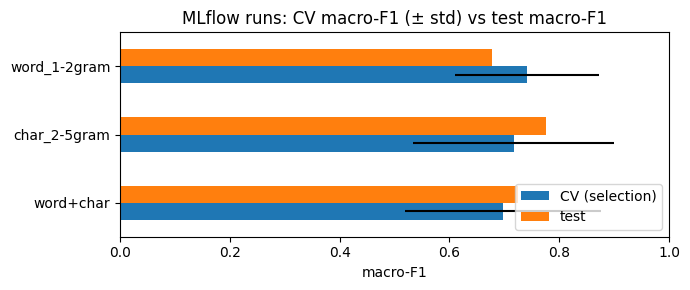

In [16]:
# Chart of the 3 runs (always works, good for a screenshot)
import matplotlib.pyplot as plt
r = runs.head(3).set_index("tags.mlflow.runName").sort_values("metrics.cv_macro_f1")  # latest training
ax = r[["metrics.cv_macro_f1", "metrics.test_macro_f1"]].plot.barh(
    xerr={"metrics.cv_macro_f1": r["metrics.cv_macro_f1_std"]}, figsize=(7, 3))
ax.set_xlim(0, 1); ax.set_xlabel("macro-F1"); ax.set_ylabel("")
ax.set_title("MLflow runs: CV macro-F1 (± std) vs test macro-F1"); ax.legend(["CV (selection)", "test"], loc="lower right")
plt.tight_layout(); plt.show()

### Open the real MLflow UI
Run the next cell, then click the link. In the UI: **Model training → Runs**, tick all 3 runs → **Compare**
to show params, metrics and the `selected=true` tag side by side.
`--allowed-hosts` lists Colab's proxy domains: MLflow 3 rejects every host except localhost ("Invalid Host header"),
and Colab serves the UI through `*.googleusercontent.com` / `*.colab.dev`.

In [17]:
mlflow_ui = subprocess.Popen(
    [sys.executable, "-m", "mlflow", "ui", "--backend-store-uri", f"sqlite:///{(PROJECT / 'mlflow.db').as_posix()}",
     "--host", "0.0.0.0", "--port", "5000",
     "--allowed-hosts", "*.googleusercontent.com,*.colab.dev,localhost,localhost:*,127.0.0.1,127.0.0.1:*",
     "--cors-allowed-origins", "https://*.googleusercontent.com,https://*.colab.dev"],
    stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
for _ in range(40):  # wait until the server answers
    try:
        requests.get("http://127.0.0.1:5000/health", timeout=1); break
    except Exception:
        time.sleep(1)
exp_id = mlflow.get_experiment_by_name("invoice-line-category").experiment_id
runs_path = f"/#/experiments/{exp_id}/runs?workflowType=machine_learning"
if IN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(5000, path=runs_path, anchor_text="Open MLflow UI (runs)")
else:
    print("Open: http://127.0.0.1:5000" + runs_path)

Open: http://127.0.0.1:5000/#/experiments/1/runs?workflowType=machine_learning


**Choice.** The CV gap between variants is smaller than one standard deviation (~0.13-0.18). With so
little data, a single held-out test of 17 lines is too noisy to pick a winner. I pick on CV, keep the simplest model, and
say plainly that **more labelled data matters more than the feature choice.**

## 5 · Evaluation

Two views, because the test split is only 17 lines (one error = 6 points):
- **held-out test set**: the honest final number
- **5-fold out-of-fold predictions over all lines**: more stable, and gives enough errors to study

In [18]:
%%writefile invoice_ml/evaluate.py
"""Task 5 - per-class precision/recall/F1, confusion matrix and model mistakes.

The test split is small (~18 lines), so we report two views:
  * held-out test set (same split as train.py) - the honest final number
  * 5-fold out-of-fold predictions over ALL lines - more stable, and gives
    enough errors to analyse
Usage:  python -m invoice_ml.evaluate
"""
from __future__ import annotations

import json

import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

from invoice_ml.model import LABELS, MODELS, ROOT, SEED, build_pipeline, load_data


def cm_table(y_true, y_pred) -> str:
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    df = pd.DataFrame(cm, index=[f"true:{l}" for l in LABELS], columns=LABELS)
    return "```\n" + df.to_string() + "\n```"


def main() -> None:
    best = json.loads((MODELS / "best_run.json").read_text(encoding="utf-8"))
    df = load_data()
    X_tr, X_te, y_tr, y_te = train_test_split(
        df["text"], df["label"], test_size=0.25, stratify=df["label"], random_state=SEED)

    pipe = build_pipeline(best["cfg"]).fit(X_tr, y_tr)
    test_pred = pipe.predict(X_te)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = cross_val_predict(build_pipeline(best["cfg"]), df["text"], df["label"], cv=cv)
    proba = cross_val_predict(build_pipeline(best["cfg"]), df["text"], df["label"], cv=cv,
                              method="predict_proba")
    df = df.assign(pred=oof, confidence=proba.max(axis=1))
    mistakes = df[df["label"] != df["pred"]].sort_values("confidence", ascending=False)

    out = [f"# Evaluation - `{best['name']}`\n",
           "## Held-out test set\n", "```",
           classification_report(y_te, test_pred, labels=LABELS, zero_division=0), "```",
           cm_table(y_te, test_pred), "",
           "## 5-fold out-of-fold (all lines)\n", "```",
           classification_report(df["label"], df["pred"], labels=LABELS, zero_division=0), "```",
           cm_table(df["label"], df["pred"]), "",
           f"## Mistakes ({len(mistakes)}) - most confident first\n",
           "| text | true | predicted | confidence |", "|---|---|---|---|"]
    out += [f"| {r.text} | {r.label} | {r.pred} | {r.confidence:.2f} |"
            for r in mistakes.itertuples()]
    report = "\n".join(out)
    (ROOT / "reports").mkdir(exist_ok=True)
    (ROOT / "reports" / "evaluation.md").write_text(report, encoding="utf-8")
    print(report)


if __name__ == "__main__":
    main()

Overwriting invoice_ml/evaluate.py


In [19]:
run("invoice_ml.evaluate")

# Evaluation - `word_1-2gram`

## Held-out test set

```
              precision    recall  f1-score   support

      cement       1.00      1.00      1.00         3
       steel       0.50      0.67      0.57         3
  aggregates       1.00      0.67      0.80         3
      blocks       0.67      0.50      0.57         4
    services       0.40      0.50      0.44         4

    accuracy                           0.65        17
   macro avg       0.71      0.67      0.68        17
weighted avg       0.69      0.65      0.66        17

```
```
                 cement  steel  aggregates  blocks  services
true:cement           3      0           0       0         0
true:steel            0      2           0       0         1
true:aggregates       0      1           2       0         0
true:blocks           0      0           0       2         2
true:services         0      1           0       1         2
```

## 5-fold out-of-fold (all lines)

```
              precision    recall  f

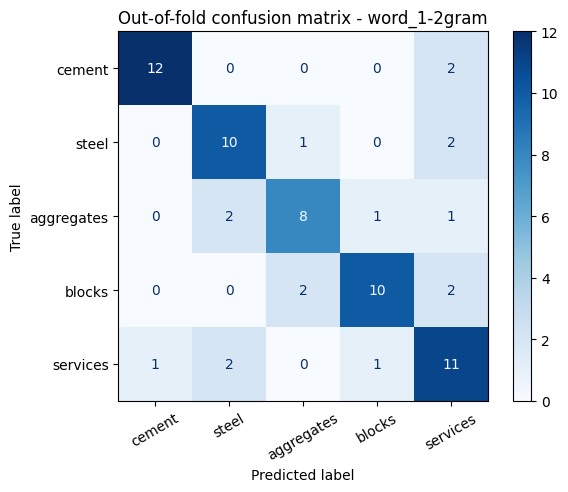

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from invoice_ml.model import LABELS, SEED, build_pipeline, load_data

best = json.loads(Path("models/best_run.json").read_text())
df = load_data()
oof = cross_val_predict(build_pipeline(best["cfg"]), df["text"], df["label"],
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
ConfusionMatrixDisplay.from_predictions(df["label"], oof, labels=LABELS, cmap="Blues")
plt.title(f"Out-of-fold confusion matrix - {best['name']}"); plt.xticks(rotation=30); plt.show()

**Three mistakes and why**
1. *Steel shuttering plate rental*: true **services**, predicted **steel** (0.79, the most confident error).
   "steel" is a strong steel word and "rental" appears only once in training. The model learns keywords, the
   same trap the AI labeller fell into. Fix: more hire/rental examples, or a rule "rental/hire → services".
2. *خرسانة جاهزة متر مكعب* (ready-mix concrete): true **cement**, predicted **services**. "خرسانة" shows up in
   "ايجار مضخة خرسانة" (pump hire = services), so the word is split across two classes. With so few examples
   the per-unit word "متر مكعب" isn't enough. Fix: more ready-mix lines in both languages.
3. *Kerb stone 50cm*: true **blocks**, predicted **aggregates**. "stone" usually means crushed stone (aggregates).
   This is a genuine ambiguity that the guide (rule 3) resolves but the data barely covers.

Common thread: keyword overlap between classes and too few examples. Low-confidence predictions (<0.5) are
mostly wrong, which supports routing them to a human.

## 6 · Deployment: FastAPI `/predict`
Loads the saved pipeline and returns the category, confidence, all class scores and a `needs_review` flag (confidence < 0.5).

In [21]:
%%writefile app/main.py
"""Task 6 - serve the selected model as POST /predict.

Run:  uvicorn app.main:app --port 8000
"""
from __future__ import annotations

import json
from pathlib import Path

import joblib
from fastapi import FastAPI
from pydantic import BaseModel, Field

ROOT = Path(__file__).resolve().parents[1]
model = joblib.load(ROOT / "models" / "model.joblib")
meta = json.loads((ROOT / "models" / "best_run.json").read_text(encoding="utf-8"))
LOW_CONFIDENCE = 0.5  # below this, route the line to a human

app = FastAPI(title="Invoice line categoriser", version="1.0")


class PredictRequest(BaseModel):
    descriptions: list[str] = Field(..., min_length=1,
                                    examples=[["Rebar T16 16mm / حديد تسليح ١٦ مم", "رمل مغسول"]])


class Prediction(BaseModel):
    description: str
    category: str
    confidence: float
    needs_review: bool
    scores: dict[str, float]


class PredictResponse(BaseModel):
    model: str
    run_id: str
    predictions: list[Prediction]


@app.get("/health")
def health():
    return {"status": "ok", "model": meta["name"], "run_id": meta["run_id"]}


@app.post("/predict", response_model=PredictResponse)
def predict(req: PredictRequest):
    probs = model.predict_proba(req.descriptions)
    classes = model.classes_
    preds = []
    for text, p in zip(req.descriptions, probs):
        i = int(p.argmax())
        preds.append(Prediction(
            description=text, category=classes[i], confidence=round(float(p[i]), 3),
            needs_review=bool(p[i] < LOW_CONFIDENCE),
            scores={c: round(float(s), 3) for c, s in zip(classes, p)}))
    return PredictResponse(model=meta["name"], run_id=meta["run_id"], predictions=preds)

Overwriting app/main.py


In [22]:
import requests
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app.main:app", "--port", "8000"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):
    try:
        print(requests.get("http://127.0.0.1:8000/health", timeout=1).json()); break
    except Exception:
        time.sleep(1)

{'status': 'ok', 'model': 'word_1-2gram', 'run_id': '4af8fed0dd5b4ca295c894af5edcc4bd'}


In [23]:
# Live call with the 6 real lines from the invoice
lines = [f"{i['description_en']} / {i['description_ar']}" for s in inv["sections"] for i in s["items"]]
req = {"descriptions": lines}
print("REQUEST:\n", json.dumps(req, ensure_ascii=False, indent=2))
resp = requests.post("http://127.0.0.1:8000/predict", json=req).json()
print("\nRESPONSE (status 200) - model", resp["model"], "from MLflow run", resp["run_id"])
display(pd.DataFrame(resp["predictions"])[["description", "category", "confidence", "needs_review"]])
print("\nRaw JSON for one line:")
print(json.dumps(resp["predictions"][1], ensure_ascii=False, indent=2))

REQUEST:
 {
  "descriptions": [
    "Portland cement 50 kg / أسمنت بورتلاند ٥٠ كجم",
    "Rebar 12 mm / حديد تسليح ١٢ مم",
    "Washed sand / رمل مغسول",
    "Concrete block 20 cm / بلوك خرساني ٢٠ سم",
    "Waterproofing membrane / رول عزل مائي",
    "Delivery charge / رسوم التوصيل"
  ]
}

RESPONSE (status 200) - model word_1-2gram from MLflow run 4af8fed0dd5b4ca295c894af5edcc4bd


,description,category,confidence,needs_review
0,Portland cement 50 kg / أسمنت بورتلاند ٥٠ كجم,cement,0.871,False
1,Rebar 12 mm / حديد تسليح ١٢ مم,steel,0.853,False
2,Washed sand / رمل مغسول,aggregates,0.857,False
3,Concrete block 20 cm / بلوك خرساني ٢٠ سم,blocks,0.841,False
4,Waterproofing membrane / رول عزل مائي,services,0.225,True
5,Delivery charge / رسوم التوصيل,services,0.831,False



Raw JSON for one line:
{
  "description": "Rebar 12 mm / حديد تسليح ١٢ مم",
  "category": "steel",
  "confidence": 0.853,
  "needs_review": false,
  "scores": {
    "aggregates": 0.038,
    "blocks": 0.034,
    "cement": 0.034,
    "services": 0.042,
    "steel": 0.853
  }
}


In [24]:
# Same call with curl (what you would show in a terminal; Linux/Colab shell syntax)
if IN_COLAB:
    get_ipython().system("curl -s -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' -d '{\"descriptions\": [\"Rebar 12 mm / حديد تسليح ١٢ مم\"]}'")

In [25]:
# Interactive Swagger docs: POST /predict -> Try it out -> Execute (a live call in the browser)
if IN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(8000, path="/docs", anchor_text="Open API docs (/docs)")
else:
    print("Open: http://127.0.0.1:8000/docs")

Open: http://127.0.0.1:8000/docs


Note the **waterproofing membrane**: the model must pick one of 5 classes it was trained on, but the
confidence is low, so `needs_review` catches it. That is the right behaviour for an out-of-taxonomy item.

## 7 · Code & documentation
The README, labelling guide and prompts are written below. In Colab, the last cell downloads the whole project as a zip.

In [26]:
%%writefile README.md
# jubii.7 Track A: Read the messy invoice

A reader-and-checker for a bilingual (Arabic/English) tax invoice and delivery note from Al Waha Building
Materials, plus a small model that sorts each line item into **cement / steel / aggregates / blocks / services**.

**Fastest way to review:** open `track_a_colab.ipynb` here on GitHub. It is committed **fully executed**, so every
output is visible: the invoice problems, MLflow runs, evaluation and the live API calls. To re-run it, open it in
Google Colab and choose Runtime → Run all, or run it locally inside this folder.

```
track_a_colab.ipynb             all 7 tasks, executed top to bottom (generated by tools/build_notebook.py)
data/invoice_extracted.json     transcription of the scan (values exactly as printed)
data/line_items_labelled.csv    69 lines: 6 from the invoice + 63 AI-generated, hand-reviewed
docs/LABELLING_GUIDE.md         5-rule labelling guide
docs/PROMPTS.md                 prompts used (extraction, data generation)
invoice_ml/text_utils.py        Arabic digit/text normalisation, Arabic amount-in-words parser
invoice_ml/check_invoice.py     Task 1: profile, recalculate, list problems
invoice_ml/model.py             TF-IDF + logistic regression variants
invoice_ml/train.py             Tasks 3-4: train, log to MLflow, select, save
invoice_ml/evaluate.py          Task 5: per-class P/R/F1, confusion matrix, mistakes
invoice_ml/extraction_accuracy.py  field / critical-field accuracy and CER of an extraction vs a ground-truth JSON
app/main.py                     Task 6: FastAPI POST /predict
mlflow.db, mlruns/              MLflow tracking store (the 3 runs) and logged models
models/                         selected model + best_run.json (used by the API)
reports/                        generated outputs (problems, profile, clean JSON, evaluation)
tools/build_notebook.py         rebuilds the notebook from the source files
```

## How to run locally (Python 3.10+)
```
python -m pip install -r requirements.txt
python -m invoice_ml.check_invoice      # Task 1 -> reports/invoice_problems.csv
python -m invoice_ml.train              # Tasks 3-4 -> mlflow.db, models/model.joblib
python -m invoice_ml.evaluate           # Task 5 -> reports/evaluation.md
mlflow ui --backend-store-uri sqlite:///mlflow.db     # http://127.0.0.1:5000
uvicorn app.main:app --port 8000                      # http://127.0.0.1:8000/docs
```
On Windows, set `PYTHONIOENCODING=utf-8` first so the Arabic text prints correctly.

Example request and response (shortened):
```
POST /predict  {"descriptions": ["Rebar 12 mm / حديد تسليح ١٢ مم"]}
-> {"model": "word_1-2gram", "predictions": [{"category": "steel", "confidence": 0.853, "needs_review": false, ...}]}
```

## Live demo: MLflow runs + API call
**On a laptop** (after `python -m invoice_ml.train`), open two terminals in this folder:
```
python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
python -m uvicorn app.main:app --port 8000
```
1. Go to http://127.0.0.1:5000. Click **Model training** (top left; MLflow 3 opens in GenAI mode) →
   experiment `invoice-line-category` → tick all 3 runs → **Compare**. This shows the params, CV/test
   macro-F1 and the `selected=true` tag.
2. Go to http://127.0.0.1:8000/docs → **POST /predict** → **Try it out** → **Execute**. You get a 200 response with the category,
   confidence and scores. Its `run_id` is the MLflow run that produced the model.

**In Colab:** Run all, then use the "Open MLflow UI" and "Open API docs" links in §4 and §6.

## 1. Data understanding
**Extraction.** The scan is read with a vision LLM (prompt in `docs/PROMPTS.md`) and checked field by field
against the image. Values are kept *exactly as printed* (Arabic digits, commas,
brackets, blanks); uncertain reads go in `_low_confidence`. Correcting during extraction would hide the
errors we are asked to find. Normalising happens in code: `٢٤` becomes 24, `(155.20)` becomes 155.20, and the Arabic
amount in words becomes 23,660.30.

**Profile:** 108 fields, each with an inferred type (number/date/id/text/missing) and a digit script. Ten values
use Arabic-Indic digits (quantities on lines 3 and 5, the PO number, and Arabic text fields), and six are blank.

**Recalculation (printed -> correct):**

| | printed | recalculated |
|---|---:|---:|
| Total before discount | 22,630.00 | 22,540.00 |
| Discount 2% on Site B | 155.20 | 155.20 |
| Taxable amount | 22,474.80 | 22,384.80 |
| VAT 5% | 1,131.50 | 1,119.24 |
| **Grand total** | **23,606.30** | **23,504.04** |

The customer is overcharged by **AED 102.26**, caused by two independent errors (line 3 and the VAT).

**Problems found: 26** (9 high, 7 medium, 4 low, 6 info). The main ones:
- Line 3, washed sand: 24 x 65 = 1,560, printed 1,650 (digit swap). It carries into the Site A subtotal and every total after it.
- VAT 1,131.50 is not 5% of the printed taxable amount (1,123.74). This is a second, independent error.
- Amount in words says 23,660.30, the figure says 23,606.30.
- Delivery D3 is dated 31/11/2026, which doesn't exist. D2 (15/11) is after the invoice date (14/11) but marked received.
- English terms say 45 days, Arabic terms say 30 days.
- Both Cash and Credit are ticked.
- Membrane: 18 of 20 billed, 2 pending (D3 not received).
- There are 3 trips but 1 delivery charge, and the address is in Ajman while prices cover "Sharjah only".
- The discount base includes the delivery charge. All signatures are blank.

## 2. Labelling
The 5-rule guide is in `docs/LABELLING_GUIDE.md`. On review, **11 of 69 AI labels (16%) were wrong**. Each original
is kept in `ai_label`, the fix is in `label`, and the reason is in `review_note`. The AI labels by keyword ("concrete block" ->
cement, "pump hire" -> cement, "sand per truck" -> services). The invoice's **waterproofing membrane** fits none of the
5 classes, so it is marked `out_of_scope` and kept out of training.

## 3. Model choice
TF-IDF + logistic regression:
- ~70 examples is far too few for fine-tuning; a linear model on n-grams is the right size.
- It is explainable (coefficients per n-gram) and fast.
- `predict_proba` gives a confidence, so low-confidence lines go to a human (`needs_review`).
- Arabic digits, alef/taa-marbuta variants and diacritics are normalised first.

## 4. MLflow
Three runs in experiment `invoice-line-category`:

| run | CV macro-F1 | test macro-F1 |
|---|---|---|
| word 1-2 gram (**selected**) | 0.742 ± 0.13 | 0.68 |
| char_wb 2-5 gram | 0.717 ± 0.18 | 0.78 |
| word + char | 0.697 ± 0.18 | 0.72 |

The model is selected on CV macro-F1 over the training split, so the test set is never used for choosing. The differences are
within one standard deviation; the honest conclusion is that more data matters more than which features we use.

## 5. Evaluation
`reports/evaluation.md` has the held-out test results (17 lines, accuracy 0.65) and 5-fold out-of-fold results over all lines
(accuracy 0.75, macro-F1 0.75), with confusion matrices and every mistake. The most confident mistake is "Steel shuttering
plate rental" (services -> steel): the model leans on keywords, just like the AI labeller.

## Known limits
- The extraction comes from a phone photo of the page, so the TRNs and VAT figure should be re-checked on paper.
  No extraction accuracy is reported: one page has no independent ground truth. `invoice_ml/extraction_accuracy.py`
  measures it once a hand-typed ground truth exists.
- 68 training lines is tiny, so metrics have wide error bars. Real invoice lines would help most.
- The taxonomy has no class for items like waterproofing membrane.
- Extraction is not automated in the repo. At 200 invoices a day I would run a vision-LLM extraction with per-field
  confidence, then this checker, and send only failed checks or low-confidence fields to a person.
- The API has no auth, rate limits or monitoring. It is a local demo.

## With more time
- Docker and CI.
- Log the evaluation report and confusion matrix to the MLflow run.
- Feed `needs_review` lines, once corrected, back into training.
- Add a supplier price list to catch wrong unit prices, not just wrong arithmetic.
- Match deliveries to lines to bill only what was received.

Overwriting README.md


In [27]:
%%writefile docs/LABELLING_GUIDE.md
# Labelling guide (5 rules)

1. **Label what is being bought, not words in the name.** Pick one of `cement`, `steel`, `aggregates`, `blocks`, `services` from the main item; ignore sizes, units and brand names.
2. **cement** = loose or bagged cement and wet/dry products made mainly of cement: ready-mix concrete, mortar, cement-based adhesive, cement additives.
3. **blocks** = any finished unit you lay by hand: concrete/hollow/solid/AAC blocks, bricks, interlock, kerb stones. "Concrete block" / "طابوق اسمنتي" is **blocks**, not cement.
4. **steel** = steel products only (rebar, mesh, binding wire, sections, pipes). **services** = labour, transport, equipment hire, fees, deposits and surcharges, *even when steel or concrete is mentioned* (e.g. rebar cutting, pump hire).
5. **aggregates** = sand, gravel, crushed stone, road base, whatever the unit (truck, m3, ton). Arabic, English and bilingual lines follow the same rules; if a line fits two classes, pick the one that drives the price and add a `review_note`; if it fits none (e.g. waterproofing membrane), label `out_of_scope` - never force it into a class.

Overwriting docs/LABELLING_GUIDE.md


In [28]:
%%writefile docs/PROMPTS.md
# Prompts used

## 1. Extraction (scan -> JSON), run on a vision LLM
```
You are transcribing a scanned bilingual (Arabic/English) UAE tax invoice + delivery note.
Return ONLY JSON matching this schema: <paste the keys of data/invoice_extracted.json>.
Rules:
- Copy every value EXACTLY as printed. Do NOT fix arithmetic, do NOT convert Arabic digits,
  do NOT fill gaps. Missing or illegible -> null, and list it in "_illegible".
- Keep line items inside their printed groups, with the printed group subtotal.
- Transcribe the handwritten note and describe the stamp (text, what it covers).
- For each field you are unsure of, add it to "_low_confidence" with a reason.
```
Why: the checker must see the *printed* errors. An LLM that "helpfully" corrects totals hides exactly the mistakes the finance team needs to catch.

## 2. Synthetic labelled lines
```
Generate 60 invoice line descriptions from a UAE building-materials supplier,
12 per category: cement, steel, aggregates, blocks, services. Half English, half Arabic
(Gulf usage), with realistic sizes/units (kg, mm, m3, truck, trip). Include hard cases:
"concrete block", "rebar cutting service", "concrete pump hire", "sand per truck".
Output CSV: text,lang,ai_label
```
Then every line was reviewed by hand against `LABELLING_GUIDE.md`; the AI label is kept in
`ai_label`, the corrected one in `label`, and every change explained in `review_note`.
Typical AI error: labelling by a keyword ("concrete", "truck", "خرسانة") instead of the item.

## 3. Coding assistant
Claude Code was used to scaffold the repo (checker, training, MLflow logging, FastAPI).
All logic, thresholds and outputs were read and run before submitting.

Overwriting docs/PROMPTS.md


In [29]:
%%writefile requirements.txt
pandas>=2.0
scikit-learn>=1.4
joblib>=1.3
mlflow>=2.14
fastapi>=0.110
uvicorn>=0.29
pydantic>=2.0

Overwriting requirements.txt


In [30]:
# In Colab: download the whole project as a zip. Locally the project is already the git repo.
if IN_COLAB:
    import shutil
    from google.colab import files
    archive = shutil.make_archive(str(PROJECT.parent / "jubii7-track-a"), "zip", PROJECT.parent, PROJECT.name)
    files.download(archive)
else:
    print("Local run: project files are already in", PROJECT.name)

Local run: project files are already in jubii7-track-a


In [31]:
# Stop the API and MLflow UI servers. In Colab they keep running for the live demo;
# run `server.terminate(); mlflow_ui.terminate()` yourself when you are done.
if not IN_COLAB:
    server.terminate(); mlflow_ui.terminate(); print("servers stopped")
else:
    print("Servers still running for the demo.")

servers stopped


**Demo checklist:** (1) the MLflow run chart and table in §4 → open the MLflow UI → Compare the 3 runs;
(2) the live `/predict` call on the 6 invoice lines in §6 → open `/docs` → Try it out → Execute.
The response carries the MLflow `run_id`, so every prediction can be traced back to the run that made the model.